Paquetes necesarios

In [3]:
import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

TAREA: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaríaj en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y mo¡ilímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 



In [17]:
import math

diametros_monedas = {2: 25.75, 1: 23.25, 0.5: 24.25, 0.2: 22.25, 0.1: 19.75, 0.05: 21.25, 0.02: 18.75, 0.01: 16.25}
diametros_calculados = {}
factor_escala = None
calibrado = False
circulos_actuales = None

def averiguar_material(det_radio, hsv_image, mascara):
    media, stddev = cv2.meanStdDev(hsv_image, mask=mascara)
    #Conseguimos el color base de las monedas(El tono)
    h = media[0][0]
    #Conseguimos la saturación de las monedas
    s = media[1][0]
    #Desviación estándar, para detectar monedas de 1 o 2 euros, ya que como las demás tienen el mismo color en toda la moneda la desviación es muy baja.
    s_std = stddev[1][0] 
    
    diametro_calculado = round((det_radio / factor_escala) * 2, 2)
    
    #Si la saturación es baja significa que es un color metálico
    if s < 40:
        return "Plata / Gris"
    
    #Colores relacionados con las monedas de cobre(rojo puro, naranja, rojo oscuro)
    elif (h >= 0 and h <= 15) or (h >= 165 and h <= 179):
        return "Cobre / Bronce"

    #Si el diámetro es grande, la desviación estándar es alta(hay varios colores) y la saturación es alta(por los dorados)
    elif diametro_calculado > 19.0 and s_std > 20 and s < 120:
        return "Desconocido / Bicolor"
        
    #Por descarte el que queda es color oro
    else:
        return "Oro / Amarillo"

def averiguar_tamaño(det_radio, material):
    
    diametro_calculado = round((det_radio / factor_escala) * 2, 2)
    
    #Con el material decartamos muchas monedas
    if material == "Cobre / Bronce":
        monedas = [0.01, 0.02, 0.05]
    elif material == "Oro / Amarillo":
        monedas = [0.1, 0.2, 0.5]
    elif material == "Desconocido / Bicolor":
        monedas = [1, 2]
    else:
        return 0
    
    
    moneda_mas_cercana = 0
    menor_umbral = 999.0
    
    #De las monedas que pueden ser coge la que tenga el diámetro más cercano al calculado
    for moneda in monedas:
        diferencia = abs(diametro_calculado - diametros_monedas[moneda])
        if diferencia < menor_umbral:
            menor_umbral = diferencia
            moneda_mas_cercana = moneda
            
    diametros_calculados[moneda_mas_cercana] = diametro_calculado
    return moneda_mas_cercana

def click_calibracion(event, x, y, flags, param):
    global factor_escala, calibrado, circulos_actuales
    
    #Detectamos si hemos tocado el clcik izquierdo para elegir la moneda, calibrado está a False ya que no hemos elegido monedas, como los circulos que estan a None
    if event == cv2.EVENT_LBUTTONDOWN and not calibrado and circulos_actuales is not None:
        #Comprobamos círculo por círculo para saber donde hemos clickeado
        for det in circulos_actuales[0]:
            x_coord, y_coord, radio = det
            distancia = math.sqrt((x - x_coord)**2 + (y - y_coord)**2)
            
            #PComprobamos si la moneda que hemos mirado, la distancia del clcik es más pequeña que el radio de la moneda es que hemos clickeado dentro
            if distancia <= radio:
                valor_str = input("Introduce el valor real de esta moneda (1, 0.5, 0.2): ")
                
                #Calculamos fator escala y lo redondeamos a 2 decimales
                try:
                    #Para calcular el factor de escala lo comparamos con el diametro real de la moneda y así sabemos a que escala estarán las demás monedas
                    valor_moneda = float(valor_str)
                    diametro_real = diametros_monedas[valor_moneda]
                    diametro_pixeles = radio * 2
                    
                    factor_escala = diametro_pixeles / diametro_real
                    factor_escala = round(factor_escala, 2)
                    
                    print(f"Factor de escala: {factor_escala} px/mm.")
                    calibrado = True
                    
                except KeyError:
                    print("Ese valor no existe. Vuelve a hacer clic.")
                except ValueError:
                    print("Por favor, introduce un número.")
                break

cap = cv2.VideoCapture(1)
cv2.namedWindow('Detector de Monedas', cv2.WINDOW_NORMAL)
cv2.resizeWindow('Detector de Monedas', 960, 720)
cv2.setMouseCallback('Detector de Monedas', click_calibracion)

while True:
    ret, frame = cap.read()
    
    if not ret:
        print("No se puedo encender la cámara.")
        break
    
    img_resultados = frame.copy()
    gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    hsv_image = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    pimg = cv2.medianBlur(gris, 7)
    
    circ = cv2.HoughCircles(
        pimg, 
        cv2.HOUGH_GRADIENT, 
        1,
        100, 
        param1=100, 
        param2=50, 
        minRadius=45, 
        maxRadius=150, 
    )
    
    if circ is not None:
        #Convertimos las coordenadas a números enteros para poder dibujarlas
        circulos_actuales = np.uint16(np.around(circ))
        total_dinero = 0.0
        
        for det in circulos_actuales[0]:
            x_coor, y_coor, det_radio = det
            
            #Mientras que no hayamos elegido nos aparecerá elegir una moneda y los círculos detectados en rojo
            if not calibrado:
                cv2.circle(img_resultados, (x_coor, y_coor), det_radio, (0, 0, 255), 2)
                cv2.putText(img_resultados, "HAZ CLIC EN UNA MONEDA", (20, 40), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
                            
            else:
                #Sirve para tener el tamaño correcto del círculo y ignorar lo demás
                mascara = np.zeros(gris.shape, dtype=np.uint8)
                cv2.circle(mascara, (x_coor, y_coor), det_radio, 255, -1)
                
                #Averiguamos el material, luego el valor y finalmente lo sumamos al dinero total
                material = averiguar_material(det_radio, hsv_image, mascara)
                valor = averiguar_tamaño(det_radio, material)
                total_dinero += valor
                
                #Ponemos un círculo verde a las monedas procesadas y su respectivo valor
                cv2.circle(img_resultados, (x_coor, y_coor), det_radio, (0, 255, 0), 2)
                cv2.putText(img_resultados, f"{valor} EUR", (x_coor - 20, y_coor), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)
                            
        if calibrado:
            #Luego de tener todas las monedas analizadas, ponemos el total de dinero en la esquina
            cv2.putText(img_resultados, f"Total: {round(total_dinero, 2)} EUR", (20, 40), 
                        cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 3)
    
    cv2.imshow('Detector de Monedas', img_resultados)
    
    tecla = cv2.waitKey(1) & 0xFF
    if tecla == ord('q'): 
        break

cap.release()
cv2.destroyAllWindows()

C:\Users\mench\AppData\Local\Temp\ipykernel_16840\1949585426.py:72: RuntimeWarning: overflow encountered in scalar subtract
  distancia = math.sqrt((x - x_coord)**2 + (y - y_coord)**2)


Factor de escala: 6.83 px/mm.


TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje `profunfop ni poara segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

In [14]:
import cv2
import numpy as np

imagen = "MPs_test.jpg"
img = cv2.imread(imagen)
gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv_img = cv2.cvtColor(img, cv2.COLOR_BGR2HSV) 
predicciones_modelo = []
centros_detectados = []

def es_duplicado(cnt):
    
    M = cv2.moments(cnt)
    cX = int(M["m10"] / M["m00"])
    cY = int(M["m01"] / M["m00"])
    
    for cx_prev, cy_prev in centros_detectados:
        if abs(cX - cx_prev) < 10 and abs(cY - cy_prev) < 10:
            return True
    
    centros_detectados.append((cX, cY))
    return False

def clasificar_microplastico(cnt, hsv_image):
    area = cv2.contourArea(cnt)
    perimetro = cv2.arcLength(cnt, True)
    
    #Si el perímetro es cero no existe nada
    if perimetro == 0:
        return "Desconocido", (128, 128, 128)
    
    #Ponemos una variable para comprobar si el borde es circular, ya que hay un microplástico que tiende a ser redondo
    circularidad = 4 * np.pi * (area / (perimetro * perimetro))
    
    #Crear una máscara individual para calcular el color exacto de ESTE contorno
    mascara_individual = np.zeros(hsv_image.shape[:2], dtype=np.uint8)
    cv2.drawContours(mascara_individual, [cnt], -1, 255, -1)
    
    media, stddev = cv2.meanStdDev(hsv_image, mask=mascara_individual)
    s = media[1][0]  #Saturación
    v = media[2][0]  #Brillo
    
    if circularidad > 0.85:
        return "PEL", (0, 255, 0) #Verde(PEL)
    elif v < 80 or (s < 50 and v < 100):
        return "TAR", (255, 0, 0) #Azul(TAR)
    elif s < 60 and v > 150:
        return "FRA", (0, 0, 255) # Rojo(FRA)
    else:
        #Como hay muchos fragmentos que no son blancos, ni negros ni redondos pues por descarte son fragmentos
        return "FRA", (0, 0, 255) #Rojo (FRA)

#Utilizo este algoritmo(K-means) ya que con mi código antiguo iba petado el sistema
def kmeans_colores_dominantes(img, K=10):
    #Convertimos la imagen en una lista larga de filas donde cada pixel tiene los valores B, G, R
    Z = img.reshape((-1, 3))
    #Pasamos a 32 bits los numeros
    Z = np.float32(Z)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
    #Encontramos esos 10 colores predominantes en la imagen
    _, label, centers = cv2.kmeans(Z, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
    #Pasamos los colores a 8 bits
    center = np.uint8(centers)
    return center, label

#Encontramos los K colores más dominantes para poder tener todos los bordes de microplásticos posibles
center, label = kmeans_colores_dominantes(img, K=10)
img_resultado = img.copy()
#Ponemos una tolerancia por si los colores son parecidos
tolerancia = 25 

for i, color in enumerate(center):
    limite_inferior = np.clip(color - tolerancia, 0, 255)
    limite_superior = np.clip(color + tolerancia, 0, 255)
    
    #Hacemos una máscara con esos límites para encontrar más fácil esos bordes
    mascara = cv2.inRange(img, limite_inferior, limite_superior)
    #Limpiamos el ruido que pueda quedar
    mascara = cv2.medianBlur(mascara, 5)
    
    contornos, _ = cv2.findContours(mascara, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)  
    
    for cnt in contornos:
        area = cv2.contourArea(cnt)
        perimetro = cv2.arcLength(cnt, True)
        
        #Ponemos un área mínimo para evitar el ruido y perímetro y área máximo
        if area < 150 or area > 3000 or perimetro > 1000:
            continue
        
        if not es_duplicado(cnt):
            etiqueta, color_dibujo = clasificar_microplastico(cnt, hsv_img)
            
            predicciones_modelo.append((cnt, etiqueta))
            cv2.drawContours(img_resultado, [cnt], -1, color_dibujo, 2)

thresh_adaptativo = cv2.adaptiveThreshold(
    gris, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
    cv2.THRESH_BINARY_INV, 11, 2
)

#Ya que para detectar los fragmentos blancos era más dificil por el fondo pues se hace una máscara y un kernel para ver los pixeles de cerca
kernel = np.ones((3,3), np.uint8)
mascara_solida = cv2.morphologyEx(thresh_adaptativo, cv2.MORPH_CLOSE, kernel)
contornos_blancos, _ = cv2.findContours(mascara_solida, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

for cnt in contornos_blancos:
    area = cv2.contourArea(cnt)
    perimetro = cv2.arcLength(cnt, True)
    
    if area < 150 or area > 3000 or perimetro > 1000:
        continue
    
    M = cv2.moments(cnt)
    if M["m00"] == 0:
        continue
    
    #Muchos bordes detectados antes se vuelven a detectar aqui, entonces se evita
    if not es_duplicado(cnt):

        etiqueta, color_dibujo = clasificar_microplastico(cnt, hsv_img)
        
        predicciones_modelo.append((cnt, etiqueta))
        cv2.drawContours(img_resultado, [cnt], -1, color_dibujo, 2)

cv2.imshow('Deteccion y Clasificacion', img_resultado)
cv2.waitKey(0)
cv2.destroyAllWindows()

Hacemos una evaluación de los resultados que hemos obtenido junto con los resultados reales

In [15]:
import cv2
import pandas as pd

df_reales = pd.read_csv("MPs_test_bbs.csv") 

y_real = []
y_pred = []

#No repetimos predicciones hechas
predicciones_usadas = set()

#Recorremos cada microplástico real del CSV
for index, fila in df_reales.iterrows():
    #Datos del CSV
    clase_real = fila['label']
    x_min = int(fila['x_min'])
    y_min = int(fila['y_min'])
    x_max = int(fila['x_max'])
    y_max = int(fila['y_max'])
    
    clase_predicha = "No Detectado"
    
    for i, (cnt_pred, etiqueta_pred) in enumerate(predicciones_modelo):

        if i in predicciones_usadas:
            continue
            
        #Encontramos el centro del microplástico
        M = cv2.moments(cnt_pred)
        if M["m00"] == 0:
            continue
        cX = int(M["m10"] / M["m00"])
        cY = int(M["m01"] / M["m00"])
        
        #Comprobamos los resultados
        if (x_min <= cX <= x_max) and (y_min <= cY <= y_max):
            clase_predicha = etiqueta_pred
            predicciones_usadas.add(i)
            break
    
    #Añadimso los datos
    y_real.append(clase_real)
    y_pred.append(clase_predicha)

print("Total elementos en y_real:", len(y_real))
print("Total elementos en y_pred:", len(y_pred))


Total elementos en y_real: 120
Total elementos en y_pred: 120


Creamos la matriz de confusión con todos los datos obtenidos

c:\Users\mench\anaconda3\envs\VC_P1\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Accuracy = 0.64
Precision = 0.77
Recall = 0.64
F1 Score = 0.66


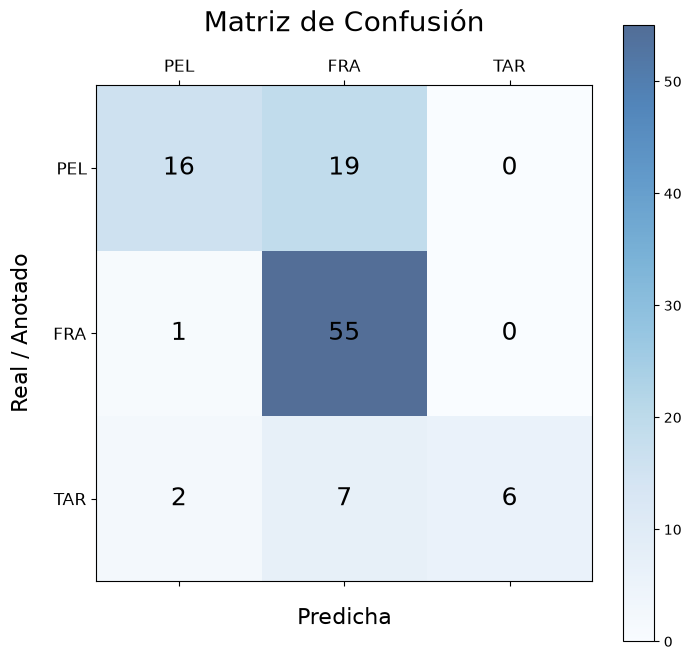

In [ ]:
import random
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

#Número de clases y elementos
n = len(y_real)
clases = ["PEL", "FRA", "TAR"]
nclases = len(clases)

#Calculamos los resultados
accuracy = accuracy_score(y_real, y_pred)
precision = precision_score(y_real, y_pred, average='weighted')
recall = recall_score(y_real, y_pred, average='weighted')
f1score = f1_score(y_real, y_pred, average='weighted')

print(f"Accuracy = {accuracy:.2f}")
print(f"Precision = {precision:.2f}")
print(f"Recall = {recall:.2f}")
print(f"F1 Score = {f1score:.2f}")

#Hacemos la matriz de confusión
conf_matrix = confusion_matrix(y_real, y_pred, labels=clases)

fig, ax = plt.subplots(figsize=(8, 8))
cax = ax.matshow(conf_matrix, cmap=plt.cm.Blues, alpha=0.7)

plt.title('Matriz de Confusión', fontsize=20, pad=20)
fig.colorbar(cax)

for (i, j), val in np.ndenumerate(conf_matrix):
    ax.text(j, i, f"{val}", ha='center', va='center', fontsize=18, color='black')

plt.xlabel('Predicha', fontsize=16, labelpad=15)
plt.ylabel('Real / Anotado', fontsize=16, labelpad=15)

plt.xticks(range(nclases), clases, fontsize=12)
plt.yticks(range(nclases), clases, fontsize=12)

plt.show()